In [4]:

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 500

amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)

score = (
    -4.5
    + 0.45 * (amount > 300)
    + 1.1 * new_device
    + 1.5 * foreign_ip
    + 0.7 * (hour < 5)
)

prob = 1 / (1 + np.exp(-score))
isFraud = rng.binomial(1, prob)

df = pd.DataFrame({
    'amount': amount.round(2),
    'hour': hour,
    'new_device': new_device,
    'foreign_ip': foreign_ip,
    'isFraud': isFraud
})

# Menampilkan dataset awal
print("Dataset awal:")
print(df.head(10))

print("\nDistribusi kelas:")
print(df['isFraud'].value_counts())

# Menyimpan dataset
df.to_csv('dataset_fraud.csv', index=False)


Dataset awal:
   amount  hour  new_device  foreign_ip  isFraud
0  201.28     9           0           0        0
1   52.46     8           0           0        0
2  314.33    17           1           0        0
3  380.15     3           0           0        0
4   21.09     5           1           0        0
5   40.36    14           0           0        0
6  168.65    16           0           0        0
7  108.18     2           1           0        0
8  145.94    12           1           0        0
9   63.24     8           0           0        0

Distribusi kelas:
isFraud
0    484
1     16
Name: count, dtype: int64


In [5]:

from sklearn.model_selection import train_test_split

X = df[['amount', 'hour', 'new_device', 'foreign_ip']]
y = df['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))


Jumlah data training: 400
Jumlah data testing: 100


In [6]:

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Prediksi data testing
y_pred = model.predict(X_test)

print("Prediksi selesai!")
print("Jumlah data testing:", len(y_test))


Prediksi selesai!
Jumlah data testing: 100


In [7]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

TN, FP, FN, TP = cm.ravel()

print("\nNilai aktual:")
print("TP =", TP)
print("TN =", TN)
print("FP =", FP)
print("FN =", FN)


Confusion Matrix:
[[96  1]
 [ 3  0]]

Nilai aktual:
TP = 0
TN = 96
FP = 1
FN = 3


In [8]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Perhitungan manual
accuracy_manual = (TP + TN) / (TP + TN + FP + FN)
precision_manual = TP / (TP + FP) if TP + FP else 0
recall_manual = TP / (TP + FN) if TP + FN else 0

f1_manual = (
    2 * precision_manual * recall_manual /
    (precision_manual + recall_manual)
    if precision_manual + recall_manual else 0
)

# Perhitungan Scikit-Learn
accuracy_sklearn = accuracy_score(y_test, y_pred)
precision_sklearn = precision_score(
    y_test, y_pred, zero_division=0
)
recall_sklearn = recall_score(
    y_test, y_pred, zero_division=0
)
f1_sklearn = f1_score(
    y_test, y_pred, zero_division=0
)

# Membandingkan hasil
hasil = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Manual': [
        accuracy_manual,
        precision_manual,
        recall_manual,
        f1_manual
    ],
    'Scikit-Learn': [
        accuracy_sklearn,
        precision_sklearn,
        recall_sklearn,
        f1_sklearn
    ]
})

print(hasil.to_string(index=False))

print("\nApakah hasil sesuai?",
      np.allclose(
          hasil['Manual'],
          hasil['Scikit-Learn']
      ))


   Metrik  Manual  Scikit-Learn
 Accuracy    0.96          0.96
Precision    0.00          0.00
   Recall    0.00          0.00
 F1-Score    0.00          0.00

Apakah hasil sesuai? True


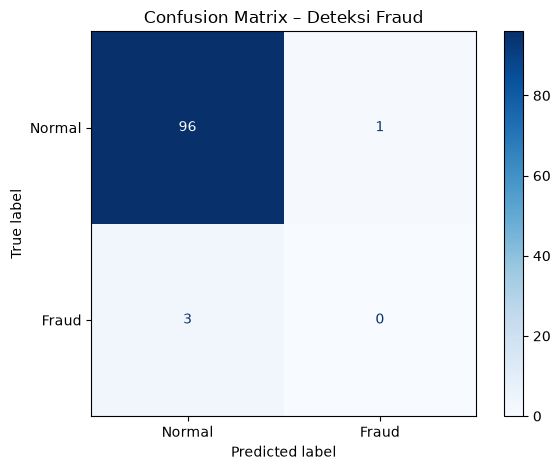

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(confusion_matrix=cm,
display_labels=['Normal','Fraud']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Deteksi Fraud')
plt.tight_layout()
plt.show()

In [10]:
print("Confusion Matrix:")
print(cm)

print("\nDetail nilai:")
print("TP:", TP)
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)

print("\nDistribusi prediksi:")
print(pd.Series(y_pred).value_counts())

print("\nDistribusi data aktual:")
print(y_test.value_counts())

Confusion Matrix:
[[96  1]
 [ 3  0]]

Detail nilai:
TP: 0
TN: 96
FP: 1
FN: 3

Distribusi prediksi:
0    99
1     1
Name: count, dtype: int64

Distribusi data aktual:
isFraud
0    97
1     3
Name: count, dtype: int64
